# Vehicle Price Prediction

Predicting a car's **MSRP** (Manufacturer's Suggested Retail Price) from its specifications, using the
[Kaggle Car Features and MSRP dataset](https://www.kaggle.com/datasets/cooperunion/cardataset) (11,914 vehicles, 16 columns).

**Author:** Youssef Saeed. Originally built as the final project for *DS588: Advanced Programming for Data Science*
(Faculty of Graduate Studies for Statistical Research, Cairo University). This is a revised version.

### What changed from the first version
| Area | First version | This version |
|---|---|---|
| Features used | `select_dtypes("object")` silently overwrote the chosen list, so the model used `model` (915 names) and dropped `number_of_doors` | Explicit, documented feature lists |
| Data leakage | Scaler and encoder fitted on all rows before the split | Everything lives inside a scikit-learn `Pipeline`, fitted on training rows only |
| Outliers | `df_Cleaned` (< \$500K) was created but never used for modelling | Scope rules applied consistently |
| Data quality | Not detected | Pre-2001 cars carry a ~\$2,000 placeholder price, so they're excluded |
| Market category | Raw string one-hot encoded (71 combinations) | Multi-hot encoded into the 10 real categories |
| Models | Linear Regression, Random Forest | Baseline, Ridge, Random Forest, Gradient Boosting |
| Metrics | Log-scale only | Log-scale **and** dollars (MAE, MAPE, % within 10%) |
| Evaluation | Random split only | Random split **plus** a harder "unseen car model" split |

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.inspection import permutation_importance

from vehicle_price import config, data, evaluate, models
from vehicle_price.features import feature_columns
from vehicle_price.train import split, unseen_model_split, fit_eval

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Chart style: one accent hue, recessive grid, muted ink.
BLUE, ORANGE, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#b4b2a9", "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e8e7e2",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10.5, "figure.dpi": 110,
})
usd = FuncFormatter(lambda v, _: f"${v/1000:,.0f}K" if v < 1e6 else f"${v/1e6:,.1f}M")

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Load the raw data

In [2]:
raw = data.standardize_columns(data.load_raw(config.DATA_PATH))
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

11,914 rows x 16 columns


,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [3]:
overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique": raw.nunique(),
})
overview[overview["missing"] > 0].sort_values("missing", ascending=False)

,dtype,missing,unique
market_category,str,3742,71
engine_hp,float64,69,356
engine_cylinders,float64,30,9
number_of_doors,float64,6,3
engine_fuel_type,str,3,10


## 2. Data quality findings

Four things matter before any modelling:

1. **Duplicates:** 715 rows are exact copies of another row. (Counting with `keep=False` gives 1,332, but that counts every copy including the one we keep.)
2. **Placeholder prices:** almost every car from model year 2000 or earlier is priced at about **\$2,000**, whatever its make. That's not a real MSRP, and it lets a model "cheat" by learning *old = \$2,000*.
3. **Hypercars:** a handful of cars cost more than \$500K (Bugatti, Maybach, Lamborghini). There are too few of them to learn from.
4. **`market_category`** is a comma-separated list of tags, not a single category.

In [4]:
dupes = raw.duplicated().sum()
print(f"Exact duplicate rows to drop: {dupes:,}")

old = raw[raw["year"] <= 2000]
print(f"Cars from 2000 or earlier: {len(old):,}  |  median MSRP ${old['msrp'].median():,.0f}  |  "
      f"share priced <= $2,500: {(old['msrp'] <= 2500).mean():.0%}")
print(f"Cars priced >= $500K: {(raw['msrp'] >= 500_000).sum()}")
print(f"Distinct market_category strings: {raw['market_category'].nunique()}  ->  distinct tags: "
      f"{raw['market_category'].dropna().str.split(',').explode().str.strip().nunique()}")

Exact duplicate rows to drop: 715
Cars from 2000 or earlier: 1,657  |  median MSRP $2,000  |  share priced <= $2,500: 78%
Cars priced >= $500K: 11
Distinct market_category strings: 71  ->  distinct tags: 10


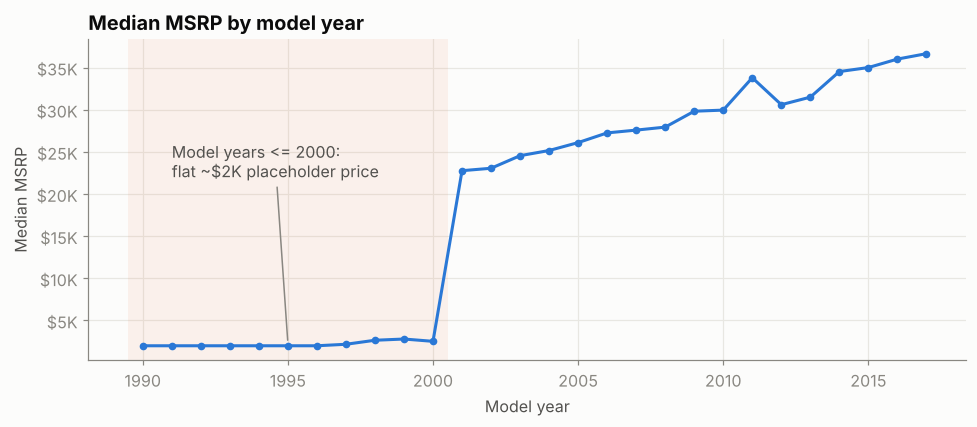

In [5]:
yearly = raw.groupby("year")["msrp"].median()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(yearly.index, yearly.values, color=BLUE, lw=2, marker="o", ms=4)
ax.axvspan(yearly.index.min() - 0.5, 2000.5, color=ORANGE, alpha=0.08, lw=0)
ax.annotate("Model years <= 2000:\nflat ~$2K placeholder price", xy=(1995, 2300), xytext=(1991, 22000),
            color="#52514e", arrowprops=dict(arrowstyle="-", color=MUTED))
ax.yaxis.set_major_formatter(usd)
ax.set(title="Median MSRP by model year", xlabel="Model year", ylabel="Median MSRP")
save(fig, "01_price_by_year")

## 3. Clean and scope the data

`data.clean()` standardizes column names, lower-cases text, drops duplicates and adds `age = 2017 - year`
(the dataset was scraped in 2017). The model's scope is **model years 2001 to 2017, priced under \$500K**.

Missing values are **not** filled here. Imputation happens inside the model pipeline so it's learned from the training rows only.

In [6]:
deduped = data.clean(data.load_raw(config.DATA_PATH), apply_scope=False)
df = data.load_clean(config.DATA_PATH)

steps = pd.DataFrame({"rows": [
    len(raw), len(deduped),
    int((deduped["year"] >= config.MIN_YEAR).sum()),
    len(df),
]}, index=["Raw", "After dropping duplicates", "Model year >= 2001", "Price < $500K (final)"])
steps

,rows
Raw,11914
After dropping duplicates,11199
Model year >= 2001,9831
Price < $500K (final),9820


## 4. Exploratory analysis

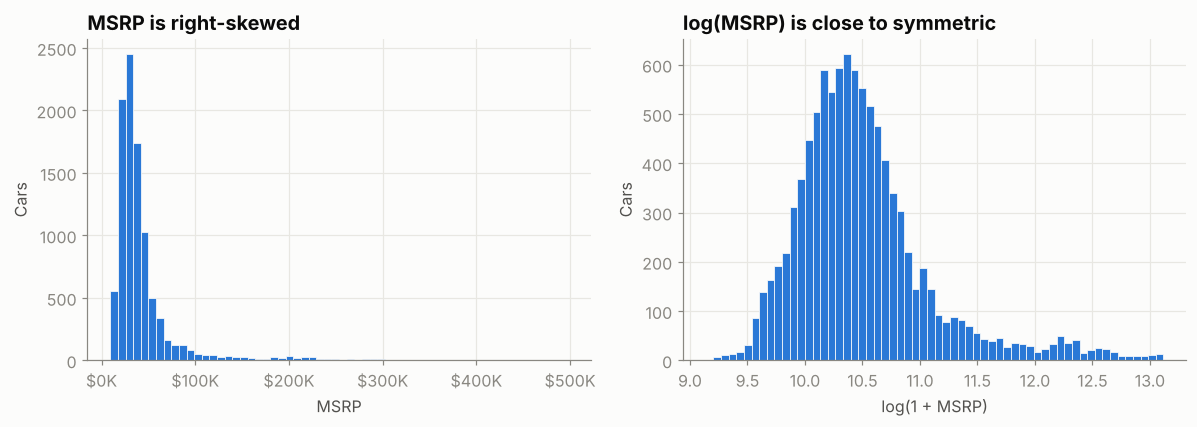

Skewness: raw 4.58  ->  log 1.42


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["msrp"], bins=60, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
axes[0].xaxis.set_major_formatter(usd)
axes[0].set(title="MSRP is right-skewed", xlabel="MSRP", ylabel="Cars")
axes[1].hist(np.log1p(df["msrp"]), bins=60, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
axes[1].set(title="log(MSRP) is close to symmetric", xlabel="log(1 + MSRP)", ylabel="Cars")
save(fig, "02_price_distribution")
print(f"Skewness: raw {df['msrp'].skew():.2f}  ->  log {np.log1p(df['msrp']).skew():.2f}")

The skew motivates training on `log(1 + price)`. Every model here is wrapped in a `TransformedTargetRegressor`,
so it **trains in log space but predicts in dollars**.

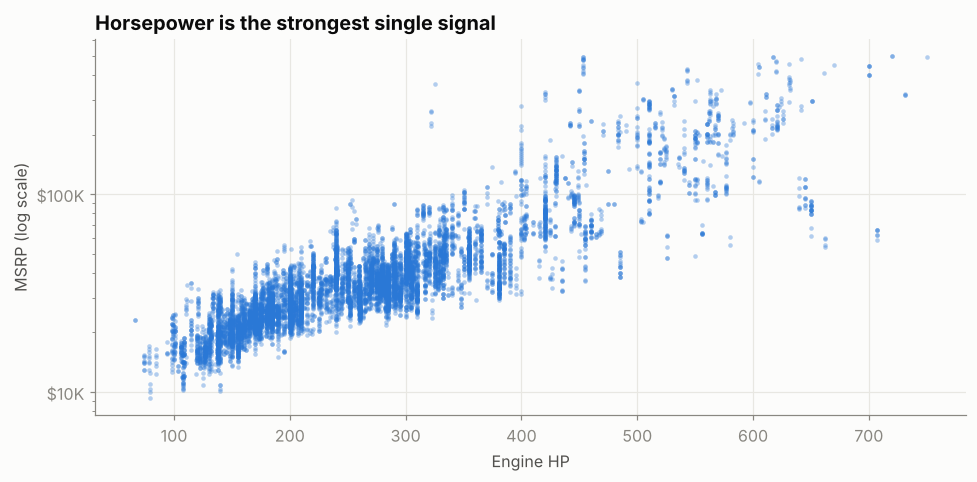

Spearman correlation (HP vs price): 0.86


In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(df["engine_hp"], df["msrp"], s=9, alpha=0.35, color=BLUE, linewidths=0)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(usd)
ax.set(title="Horsepower is the strongest single signal", xlabel="Engine HP", ylabel="MSRP (log scale)")
save(fig, "03_hp_vs_price")
print(f"Spearman correlation (HP vs price): {df['engine_hp'].corr(df['msrp'], method='spearman'):.2f}")

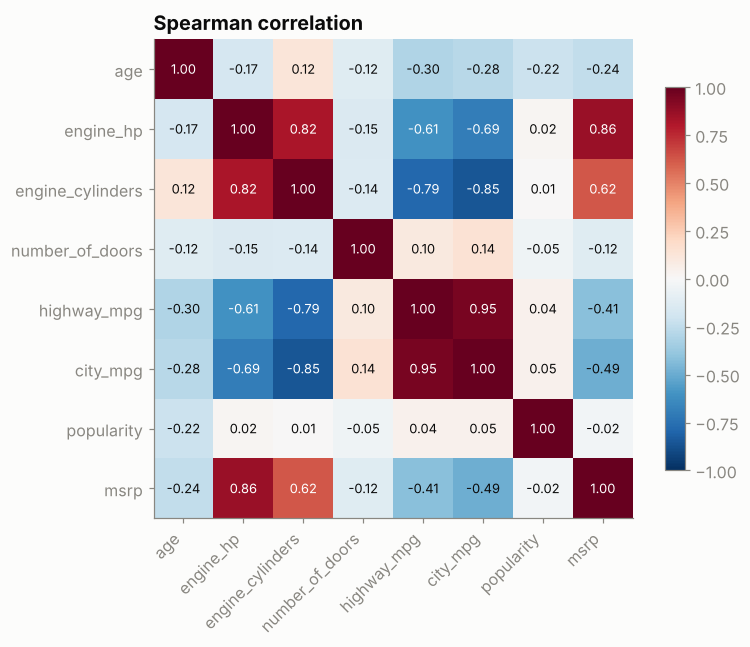

In [9]:
num = config.NUMERIC_FEATURES + ["msrp"]
corr = df[num].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num)), num, rotation=45, ha="right")
ax.set_yticks(range(len(num)), num)
ax.grid(False)
for i in range(len(num)):
    for j in range(len(num)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="white" if abs(v) > 0.6 else INK)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Spearman correlation")
save(fig, "04_correlation")

- `engine_hp` and `engine_cylinders` move together, and so do `city_mpg` and `highway_mpg`. That's expected multicollinearity, which tree models handle fine and Ridge regularizes.
- Within this scope, `age` has only a weak link to price (Spearman about -0.24). On the raw data, year and price correlate at about +0.52, and most of that comes from the \$2,000 placeholder rows.
- `popularity` has exactly one value per make, so it adds nothing beyond `make`. It's kept for completeness.

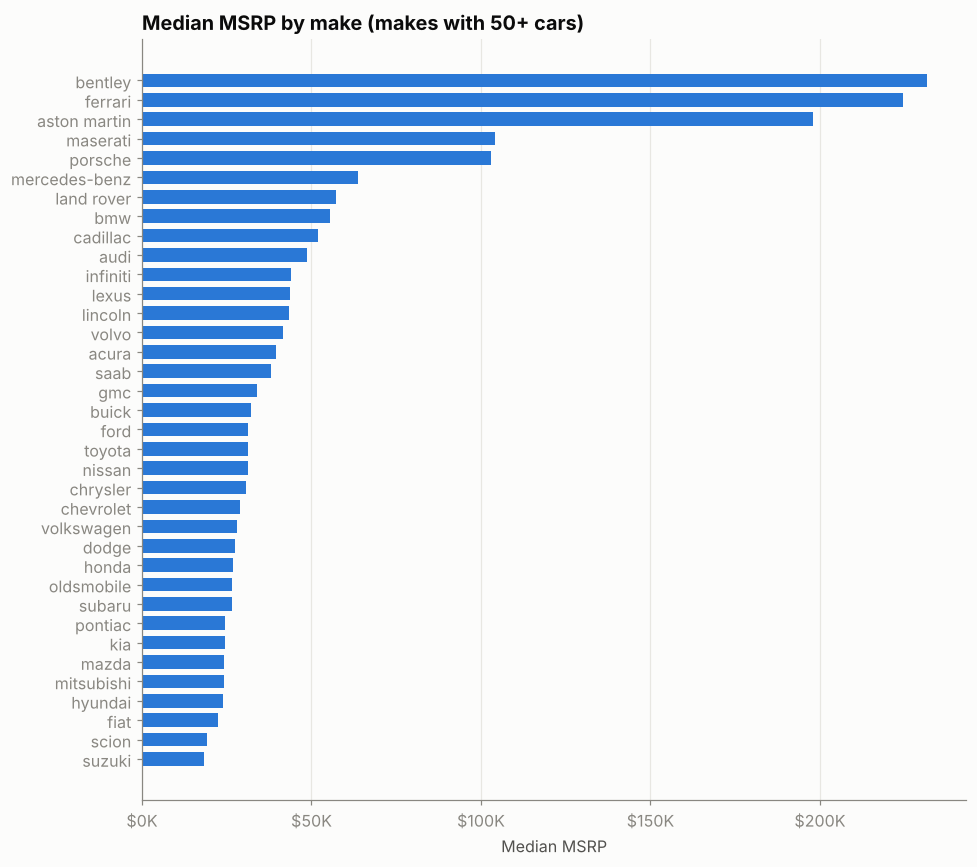

In [10]:
top = df.groupby("make")["msrp"].agg(["median", "count"]).query("count >= 50").sort_values("median")
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top.index, top["median"], color=BLUE, height=0.7)
ax.xaxis.set_major_formatter(usd)
ax.set(title="Median MSRP by make (makes with 50+ cars)", xlabel="Median MSRP")
ax.grid(axis="y", visible=False)
save(fig, "05_price_by_make")

## 5. Modelling

- **Split:** 80% train / 20% test (random, `random_state=40`).
- **Preprocessing** (see `src/vehicle_price/features.py`):
  - numeric: median imputation, plus scaling for Ridge only
  - categorical: most-frequent imputation and one-hot encoding (categories with fewer than 5 cars are grouped)
  - `market_category`: multi-hot encoding
- **Models:**
  - median-price baseline (any model must beat it)
  - Ridge Regression
  - Random Forest
  - Histogram Gradient Boosting

In [11]:
train, test = split(df)
print(f"Train {len(train):,} | Test {len(test):,}")

results, fitted = {}, {}
for name in models.MODEL_NAMES:
    fitted[name], results[models.PRETTY[name]] = fit_eval(name, train, test)

comparison = evaluate.format_table(results)
cols = ["mae_usd", "mape_pct", "median_ape_pct", "within_10pct", "r2_log", "rmse_log", "r2_usd"]
comparison[cols].style.format({
    "mae_usd": "${:,.0f}", "mape_pct": "{:.1f}%", "median_ape_pct": "{:.1f}%", "within_10pct": "{:.1f}%",
    "r2_log": "{:.3f}", "rmse_log": "{:.3f}", "r2_usd": "{:.3f}",
})

Train 7,856 | Test 1,964


,mae_usd,mape_pct,median_ape_pct,within_10pct,r2_log,rmse_log,r2_usd
Baseline (median price),"$20,796",36.8%,28.0%,19.5%,-0.024,0.588,-0.068
Ridge Regression,"$6,481",11.4%,9.3%,52.4%,0.936,0.147,0.887
Random Forest,"$3,316",7.5%,6.2%,72.4%,0.973,0.096,0.976
Gradient Boosting,"$3,097",6.9%,5.7%,75.6%,0.976,0.090,0.978


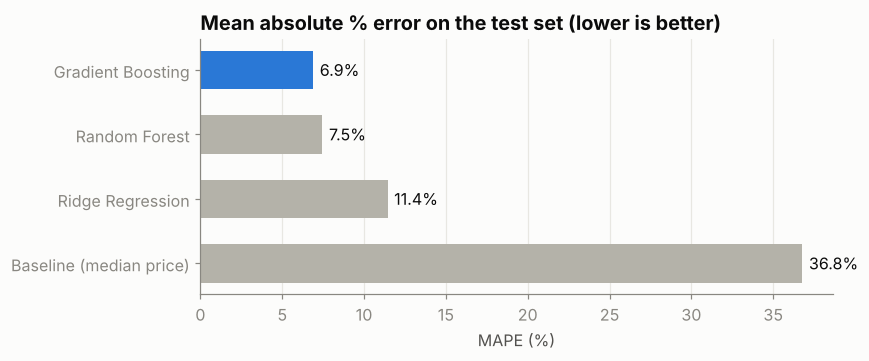

In [12]:
order = comparison["mape_pct"].sort_values(ascending=False)
best = order.drop(models.PRETTY["baseline"]).idxmin()
fig, ax = plt.subplots(figsize=(8, 3.4))
bars = ax.barh(order.index, order.values, color=[BLUE if i == best else GRAY for i in order.index], height=0.6)
for b, v in zip(bars, order.values):
    ax.text(v + 0.4, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center", color=INK)
ax.set(title="Mean absolute % error on the test set (lower is better)", xlabel="MAPE (%)")
ax.grid(axis="y", visible=False)
save(fig, "06_model_comparison")

## 6. Best model: diagnostics

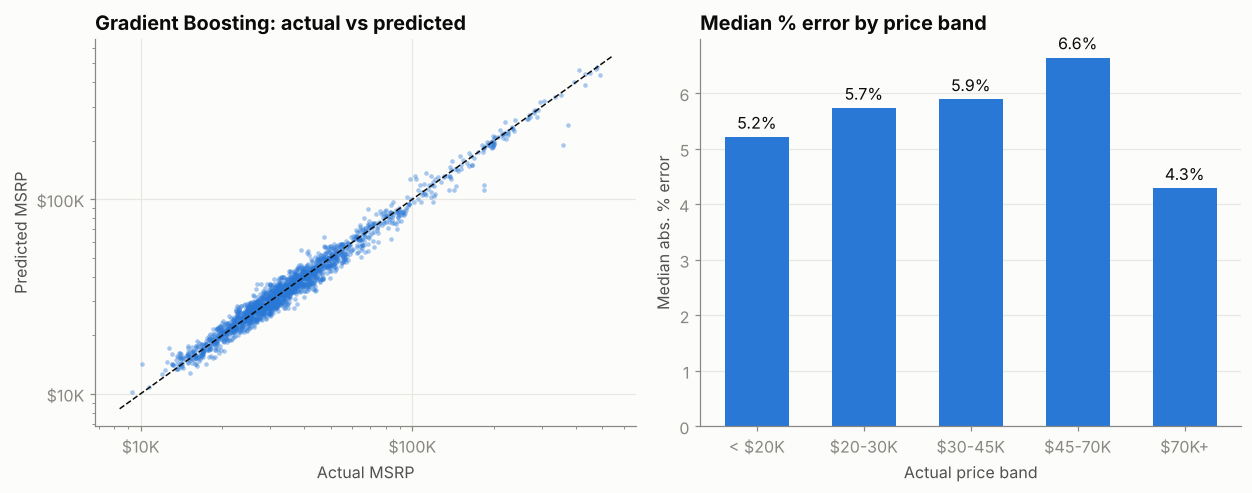

In [13]:
best_key = {v: k for k, v in models.PRETTY.items()}[best]
model = fitted[best_key]
y_true = test["msrp"].to_numpy()
y_pred = model.predict(test[feature_columns()])
ape = np.abs(y_pred - y_true) / y_true

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
ax = axes[0]
ax.scatter(y_true, y_pred, s=9, alpha=0.4, color=BLUE, linewidths=0)
lims = [y_true.min() * 0.9, y_true.max() * 1.1]
ax.plot(lims, lims, color=INK, lw=1, ls="--")
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(usd); ax.yaxis.set_major_formatter(usd)
ax.set(title=f"{best}: actual vs predicted", xlabel="Actual MSRP", ylabel="Predicted MSRP")

bands = pd.cut(y_true, [0, 20_000, 30_000, 45_000, 70_000, 500_000],
               labels=["< $20K", "$20-30K", "$30-45K", "$45-70K", "$70K+"])
by_band = pd.Series(ape * 100).groupby(bands, observed=True).median()
ax = axes[1]
ax.bar(by_band.index.astype(str), by_band.values, color=BLUE, width=0.6)
for i, v in enumerate(by_band.values):
    ax.text(i, v + 0.15, f"{v:.1f}%", ha="center", color=INK)
ax.set(title="Median % error by price band", xlabel="Actual price band", ylabel="Median abs. % error")
ax.grid(axis="x", visible=False)
save(fig, "07_best_model_diagnostics")

Predictions follow the diagonal closely across the whole price range. Relative error stays similar from
budget to luxury cars, which is what you'd expect from training on log price.

## 7. A harder test: car models the model has never seen

With a random split, the 2015 and 2016 versions of the same car can land on opposite sides of the split, so the test is partly memory.
A stricter question: **can it price a car model it has never seen?** Here every model name (e.g. `camry`) goes entirely to train or entirely to test.

In [14]:
g_train, g_test = unseen_model_split(df)
assert not set(g_train["model"]) & set(g_test["model"])
_, unseen = fit_eval(best_key, g_train, g_test)
pd.DataFrame({"Random split": results[best], "Unseen car models": unseen}).loc[
    ["mae_usd", "mape_pct", "within_10pct", "r2_log"]].round(3)

,Random split,Unseen car models
mae_usd,3097.142,5668.171
mape_pct,6.892,10.171
within_10pct,75.560,58.662
r2_log,0.976,0.957


Error rises on unseen car models, as it should. The score is still strong, so the model has learned how specs relate to price
rather than memorizing names. This is also why the free-text `model` column is **not** used as a feature:
it slightly helps the random split but **hurts** on unseen models (see `reports/metrics.json`).

## 8. What drives the price?

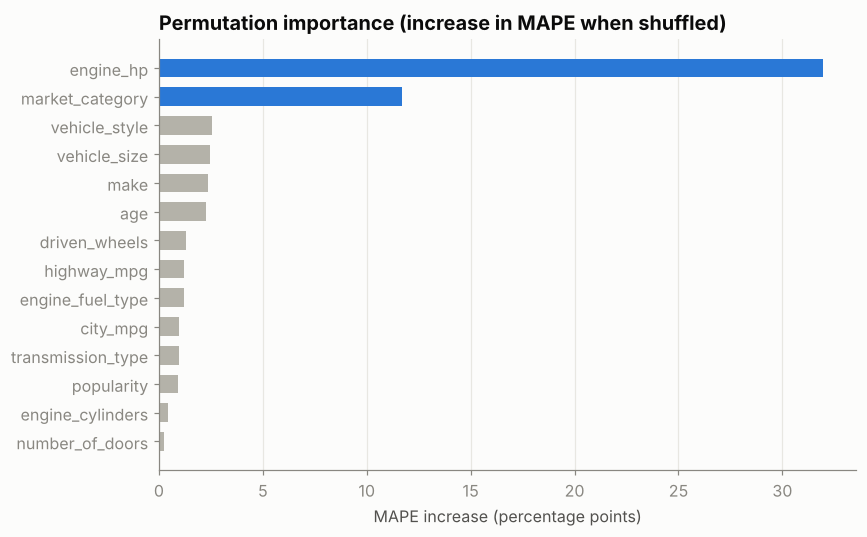

,MAPE increase (pp)
engine_hp,31.96
market_category,11.72
vehicle_style,2.57
vehicle_size,2.46
make,2.36
age,2.29
driven_wheels,1.28
highway_mpg,1.21
engine_fuel_type,1.19
city_mpg,0.99


In [15]:
X_test = test[feature_columns()]
perm = permutation_importance(model, X_test, test["msrp"], scoring="neg_mean_absolute_percentage_error",
                              n_repeats=5, random_state=config.RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean * 100, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, color=[BLUE if v >= imp.max() * 0.2 else GRAY for v in imp.values], height=0.65)
ax.set(title="Permutation importance (increase in MAPE when shuffled)", xlabel="MAPE increase (percentage points)")
ax.grid(axis="y", visible=False)
save(fig, "08_feature_importance")
imp.sort_values(ascending=False).round(2).to_frame("MAPE increase (pp)")

Permutation importance is measured on the **original columns**, so a one-hot feature like `make` is scored as one unit
instead of being split across 40+ dummy columns. That fixes a common way impurity-based importance misleads.

## 9. Using the model

In [16]:
new_car = pd.DataFrame([{
    "Make": "Toyota", "Model": "Camry", "Year": 2017, "Engine Fuel Type": "regular unleaded",
    "Engine HP": 178, "Engine Cylinders": 4, "Transmission Type": "AUTOMATIC",
    "Driven_Wheels": "front wheel drive", "Number of Doors": 4, "Market Category": None,
    "Vehicle Size": "Midsize", "Vehicle Style": "Sedan", "highway MPG": 33, "city mpg": 24, "Popularity": 2031,
}])
from vehicle_price.predict import prepare
print(f"Estimated MSRP: ${model.predict(prepare(new_car))[0]:,.0f}")

Estimated MSRP: $24,746


## 10. Conclusions

- **Gradient Boosting** is the best model, with roughly **7% mean error** and three out of four test cars priced within 10% of their MSRP.
- On car models it has never seen, error rises to about **10%**. That's a more honest estimate of real-world performance.
- **Horsepower** is by far the biggest driver, followed by **market category** (luxury, performance, exotic...). Vehicle style, size, make and age add smaller refinements.
- The first version's R² of 0.986 was inflated by placeholder prices and preprocessing leakage. The numbers here are lower but trustworthy.

**Limitations:**
- These are list prices (MSRP) from 1990 to 2017 US data, not used-car market prices.
- Trims of the same model share most specs, so the model can't see options or packages that change the price.